In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import os

print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)
print("TensorFlow Version:", tf.__version__)

print("\nAll Libraries Loaded Successfully!")

NumPy Version: 2.3.5
Pandas Version: 2.3.3
TensorFlow Version: 2.21.0

All Libraries Loaded Successfully!


In [2]:

import numpy as np
import pandas as pd

# Reproducible results
np.random.seed(42)

# Number of employees
n = 500

experience_months = np.random.randint(1, 121, n)
working_hours_per_day = np.round(np.random.uniform(5, 10, n), 1)
working_days_per_month = np.random.randint(20, 27, n)
projects_completed = np.random.randint(0, 16, n)
overtime_hours = np.random.randint(0, 31, n)

monthly_salary = (
    15000
    + (experience_months * 450)
    + (working_hours_per_day * 1800)
    + (working_days_per_month * 300)
    + (projects_completed * 700)
    + (overtime_hours * 250)
)


noise = np.random.normal(0, 3500, n)

monthly_salary = monthly_salary + noise


monthly_salary = np.maximum(monthly_salary, 15000)

monthly_salary = np.round(monthly_salary, 0)

df = pd.DataFrame({
    "Experience_Months": experience_months,
    "Working_Hours_Per_Day": working_hours_per_day,
    "Working_Days_Per_Month": working_days_per_month,
    "Projects_Completed": projects_completed,
    "Overtime_Hours": overtime_hours,
    "Monthly_Salary": monthly_salary
})

df["Monthly_Salary"] = df["Monthly_Salary"].astype(int)


df.to_csv("salary_dataset.csv", index=False)

print("Dataset created successfully!")
print("Total Records:", len(df))
print("CSV file saved as: salary_dataset.csv")


df.head(10)

Dataset created successfully!
Total Records: 500
CSV file saved as: salary_dataset.csv


,Experience_Months,Working_Hours_Per_Day,Working_Days_Per_Month,Projects_Completed,Overtime_Hours,Monthly_Salary
0,103,9.6,26,12,7,92226
1,52,7.6,24,13,17,70205
2,93,7.5,24,0,27,81786
3,15,9.0,24,12,29,63932
4,107,8.2,26,13,19,98528
5,72,8.5,23,4,29,84017
6,61,9.0,23,11,14,74393
7,21,9.5,24,8,26,61826
8,103,6.7,21,15,30,94786
9,83,6.9,22,7,6,85278


In [3]:
import numpy as np
import pandas as pd

np.random.seed(42)

n = 500

experience_months = np.random.randint(1, 61, n)

working_hours_per_day = np.round(
    np.random.uniform(5, 10, n), 1
)

working_days_per_month = np.random.randint(
    20, 27, n
)

overtime_hours_per_month = np.random.randint(
    0, 31, n
)

monthly_salary = (
    18000
    + (experience_months * 900)
    + ((working_hours_per_day - 5) * 3500)
    + ((working_days_per_month - 20) * 500)
    + (overtime_hours_per_month * 300)
)

noise = np.random.normal(0, 2500, n)

monthly_salary = monthly_salary + noise

monthly_salary = np.maximum(
    monthly_salary,
    18000
)

monthly_salary = np.round(
    monthly_salary
).astype(int)

df = pd.DataFrame({
    "Experience_Months": experience_months,
    "Working_Hours_Per_Day": working_hours_per_day,
    "Working_Days_Per_Month": working_days_per_month,
    "Overtime_Hours_Per_Month": overtime_hours_per_month,
    "Monthly_Salary": monthly_salary
})

df.to_csv(
    "salary_dataset.csv",
    index=False
)

print("Dataset Created Successfully!")
print("Total Records:", len(df))
print("CSV Saved: salary_dataset.csv")

df.head(10)

Dataset Created Successfully!
Total Records: 500
CSV Saved: salary_dataset.csv


,Experience_Months,Working_Hours_Per_Day,Working_Days_Per_Month,Overtime_Hours_Per_Month,Monthly_Salary
0,39,7.6,24,29,77114
1,52,7.5,24,16,79199
2,29,9.0,24,28,72831
3,15,8.2,26,29,57088
4,43,8.5,23,20,82371
5,8,9.0,23,11,42940
6,21,9.5,24,24,60966
7,39,6.7,21,15,58983
8,58,6.9,22,23,86178
9,19,5.5,26,11,44088


In [4]:
print("Dataset Shape:")
print(df.shape)

print("\nFirst 10 Records:")
display(df.head(10))

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape:
(500, 5)

First 10 Records:


,Experience_Months,Working_Hours_Per_Day,Working_Days_Per_Month,Overtime_Hours_Per_Month,Monthly_Salary
0,39,7.6,24,29,77114
1,52,7.5,24,16,79199
2,29,9.0,24,28,72831
3,15,8.2,26,29,57088
4,43,8.5,23,20,82371
5,8,9.0,23,11,42940
6,21,9.5,24,24,60966
7,39,6.7,21,15,58983
8,58,6.9,22,23,86178
9,19,5.5,26,11,44088



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Experience_Months         500 non-null    int32  
 1   Working_Hours_Per_Day     500 non-null    float64
 2   Working_Days_Per_Month    500 non-null    int32  
 3   Overtime_Hours_Per_Month  500 non-null    int32  
 4   Monthly_Salary            500 non-null    int64  
dtypes: float64(1), int32(3), int64(1)
memory usage: 13.8 KB

Missing Values:
Experience_Months           0
Working_Hours_Per_Day       0
Working_Days_Per_Month      0
Overtime_Hours_Per_Month    0
Monthly_Salary              0
dtype: int64

Statistical Summary:


,Experience_Months,Working_Hours_Per_Day,Working_Days_Per_Month,Overtime_Hours_Per_Month,Monthly_Salary
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,31.396000,7.464200,22.964000,15.136000,60844.542000
std,17.335982,1.464975,2.029518,9.051041,16586.314574
min,1.000000,5.100000,20.000000,0.000000,21072.000000
25%,17.750000,6.200000,21.000000,7.000000,47585.750000
50%,32.000000,7.500000,23.000000,15.000000,61018.500000
75%,46.000000,8.800000,25.000000,24.000000,73618.250000
max,60.000000,10.000000,26.000000,30.000000,100483.000000


In [5]:
X = df[
    [
        "Experience_Months",
        "Working_Hours_Per_Day",
        "Working_Days_Per_Month",
        "Overtime_Hours_Per_Month"
    ]
]

y = df["Monthly_Salary"]

print("Input Features:")
display(X.head())

print("\nTarget Salary:")
display(y.head())

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

Input Features:


,Experience_Months,Working_Hours_Per_Day,Working_Days_Per_Month,Overtime_Hours_Per_Month
0,39,7.6,24,29
1,52,7.5,24,16
2,29,9.0,24,28
3,15,8.2,26,29
4,43,8.5,23,20



Target Salary:


0    77114
1    79199
2    72831
3    57088
4    82371
Name: Monthly_Salary, dtype: int64


X Shape: (500, 4)
y Shape: (500,)


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (400, 4)
Testing Data: (100, 4)
Training Target: (400,)
Testing Target: (100,)


In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling Completed!")
print("X_train_scaled Shape:", X_train_scaled.shape)
print("X_test_scaled Shape:", X_test_scaled.shape)

Scaling Completed!
X_train_scaled Shape: (400, 4)
X_test_scaled Shape: (100, 4)


In [8]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

model = Sequential([
    Dense(64, activation="relu", input_shape=(4,)),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1)
])

model.summary()

C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

print("ANN Model Compiled Successfully!")

ANN Model Compiled Successfully!


In [10]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

print("Model Training Completed!")

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - loss: 4014151680.0000 - mae: 61067.2930 - val_loss: 3862487552.0000 - val_mae: 59896.6133
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 4013968128.0000 - mae: 61065.8359 - val_loss: 3862228224.0000 - val_mae: 59894.5117
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 4013531648.0000 - mae: 61062.4609 - val_loss: 3861620224.0000 - val_mae: 59889.6133
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 4012530176.0000 - mae: 61054.6562 - val_loss: 3860252160.0000 - val_mae: 59878.5820
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 4010478336.0000 - mae: 61038.3320 - val_loss: 3857481216.0000 - val_mae: 59856.4258
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 4006436096.0000 - mae: 61007.0859 - val_loss: 3852470272.0000 - val_mae: 59816.5508
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 3999468288.0000 - mae: 60953.1445 - val_loss: 3844009984.0000 - val_mae: 597

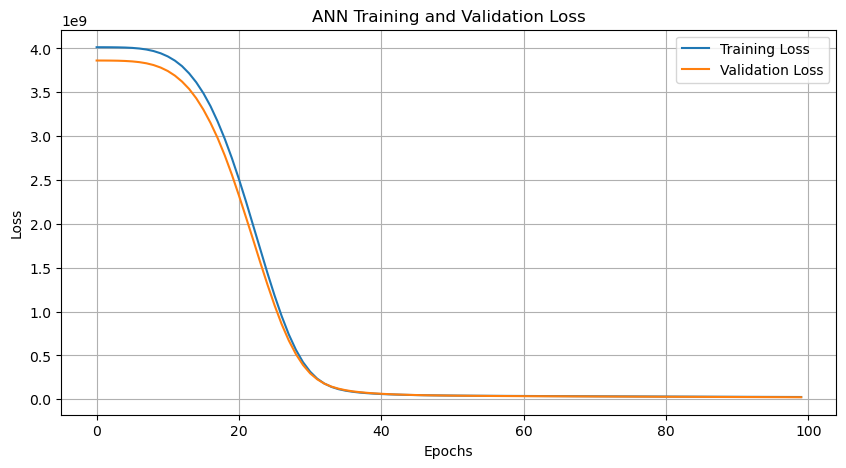

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("ANN Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [12]:
y_pred = model.predict(X_test_scaled)

y_pred = y_pred.flatten()

print("Prediction Completed!")

print("\nFirst 10 Actual Salaries:")
print(y_test.values[:10])

print("\nFirst 10 Predicted Salaries:")
print(np.round(y_pred[:10]).astype(int))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Prediction Completed!

First 10 Actual Salaries:
[40685 34588 75181 60427 77064 40675 81365 47406 59928 80675]

First 10 Predicted Salaries:
[40738 38813 71087 60820 77794 34711 76683 48495 53971 73553]


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("---------------------------")
print("MAE  :", round(mae, 2))
print("MSE  :", round(mse, 2))
print("RMSE :", round(rmse, 2))
print("R² Score:", round(r2, 4))

Model Evaluation
---------------------------
MAE  : 3349.99
MSE  : 18173782.0
RMSE : 4263.07
R² Score: 0.9243


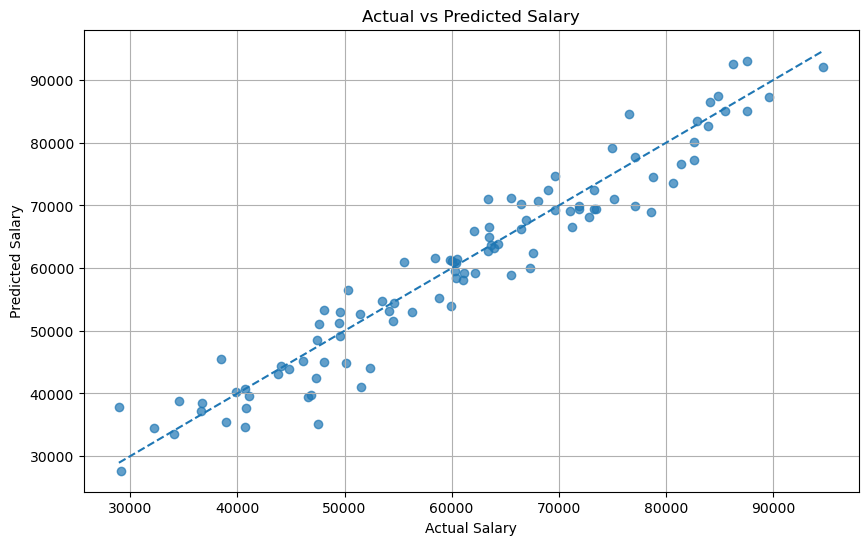

In [14]:
plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted Salary")
plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.grid(True)

plt.show()

In [15]:
model.save("salary_ann_model.keras")

print("ANN Model Saved Successfully!")
print("File Name: salary_ann_model.keras")

ANN Model Saved Successfully!
File Name: salary_ann_model.keras


In [16]:
import joblib

joblib.dump(scaler, "salary_scaler.pkl")

print("Scaler Saved Successfully!")
print("File Name: salary_scaler.pkl")

Scaler Saved Successfully!
File Name: salary_scaler.pkl


In [17]:
from tensorflow.keras.models import load_model
import joblib

loaded_model = load_model("salary_ann_model.keras")

loaded_scaler = joblib.load("salary_scaler.pkl")

print("Model Loaded Successfully!")
print("Scaler Loaded Successfully!")

Model Loaded Successfully!
Scaler Loaded Successfully!


In [18]:
experience_months = 12
working_hours_per_day = 10
working_days_per_month = 26
overtime_hours_per_month = 15

user_data = np.array([
    [
        experience_months,
        working_hours_per_day,
        working_days_per_month,
        overtime_hours_per_month
    ]
])

user_data_scaled = loaded_scaler.transform(user_data)

predicted_salary = loaded_model.predict(
    user_data_scaled,
    verbose=0
)

predicted_salary = predicted_salary[0][0]

print("Experience:", experience_months, "Months")
print("Working Hours:", working_hours_per_day, "Hours/Day")
print("Working Days:", working_days_per_month, "Days/Month")
print("Overtime:", overtime_hours_per_month, "Hours/Month")

print("\nPredicted Monthly Salary: ₹", round(predicted_salary))

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Experience: 12 Months
Working Hours: 10 Hours/Day
Working Days: 26 Days/Month
Overtime: 15 Hours/Month

Predicted Monthly Salary: ₹ 61440


In [19]:
!pip install streamlit

Defaulting to user installation because normal site-packages is not writeable
  Attempting uninstall: protobuf
    Found existing installation: protobuf 7.36.1
    Uninstalling protobuf-7.36.1:
      Successfully uninstalled protobuf-7.36.1


  You can safely remove it manually.


In [20]:
import streamlit as st

print("Streamlit Version:", st.__version__)

Streamlit Version: 1.51.0


In [21]:
app_code = '''
import streamlit as st
import numpy as np
import joblib
from tensorflow.keras.models import load_model

st.set_page_config(
    page_title="ANN Salary Predictor",
    page_icon="💰",
    layout="wide"
)

model = load_model("salary_ann_model.keras")
scaler = joblib.load("salary_scaler.pkl")

st.title("💰 ANN Salary Prediction")
st.write("Enter your work details to predict your monthly salary.")

st.divider()

col1, col2 = st.columns(2)

with col1:
    experience_months = st.number_input(
        "Experience (Months)",
        min_value=1,
        max_value=120,
        value=12,
        step=1
    )

    working_hours = st.number_input(
        "Working Hours Per Day",
        min_value=1.0,
        max_value=24.0,
        value=8.0,
        step=0.5
    )

with col2:
    working_days = st.number_input(
        "Working Days Per Month",
        min_value=1,
        max_value=31,
        value=26,
        step=1
    )

    overtime_hours = st.number_input(
        "Overtime Hours Per Month",
        min_value=0,
        max_value=200,
        value=10,
        step=1
    )

st.divider()

if st.button("🔮 Predict Salary", use_container_width=True):

    user_data = np.array([
        [
            experience_months,
            working_hours,
            working_days,
            overtime_hours
        ]
    ])

    user_data_scaled = scaler.transform(user_data)

    prediction = model.predict(
        user_data_scaled,
        verbose=0
    )

    salary = prediction[0][0]

    st.success("Salary Prediction Completed!")

    st.metric(
        "Predicted Monthly Salary",
        f"₹ {salary:,.0f}"
    )

    st.metric(
        "Predicted Annual Salary",
        f"₹ {salary * 12:,.0f}"
    )
'''

with open("app.py", "w", encoding="utf-8") as file:
    file.write(app_code)

print("app.py created successfully!")

app.py created successfully!


In [22]:
import os

print(os.getcwd())

C:\Users\ASUS


In [1]:
app_code = '''
import streamlit as st
import numpy as np
import joblib
import os
from tensorflow.keras.models import load_model

st.set_page_config(
    page_title="ANN Salary Predictor",
    page_icon="💰",
    layout="wide"
)

BASE_DIR = os.path.dirname(os.path.abspath(__file__))

model_path = os.path.join(BASE_DIR, "salary_ann_model.keras")
scaler_path = os.path.join(BASE_DIR, "salary_scaler.pkl")

model = load_model(model_path)
scaler = joblib.load(scaler_path)

st.title("💰 ANN Salary Prediction")
st.write("Enter your work details to predict your monthly salary.")

st.divider()

col1, col2 = st.columns(2)

with col1:
    experience_months = st.number_input(
        "Experience (Months)",
        min_value=1,
        max_value=120,
        value=12,
        step=1
    )

    working_hours = st.number_input(
        "Working Hours Per Day",
        min_value=1.0,
        max_value=24.0,
        value=8.0,
        step=0.5
    )

with col2:
    working_days = st.number_input(
        "Working Days Per Month",
        min_value=1,
        max_value=31,
        value=26,
        step=1
    )

    overtime_hours = st.number_input(
        "Overtime Hours Per Month",
        min_value=0,
        max_value=200,
        value=10,
        step=1
    )

st.divider()

if st.button("🔮 Predict Salary", use_container_width=True):

    user_data = np.array([
        [
            experience_months,
            working_hours,
            working_days,
            overtime_hours
        ]
    ])

    user_data_scaled = scaler.transform(user_data)

    prediction = model.predict(
        user_data_scaled,
        verbose=0
    )

    salary = prediction[0][0]

    st.success("Salary Prediction Completed!")

    st.metric(
        "Predicted Monthly Salary",
        f"₹ {salary:,.0f}"
    )

    st.metric(
        "Predicted Annual Salary",
        f"₹ {salary * 12:,.0f}"
    )
'''

with open("app.py", "w", encoding="utf-8") as file:
    file.write(app_code)

print("app.py Updated Successfully!")

app.py Updated Successfully!
